# EXAMEN FINAL

#### Emily Juárez de León 20250813

In [1]:
#librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [14]:
#Carga del dataset
df = sns.load_dataset('exercise')
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (90, 6)


,Unnamed: 0,id,diet,pulse,time,kind
0,0,1,low fat,85,1 min,rest
1,1,1,low fat,85,15 min,rest
2,2,1,low fat,88,30 min,rest
3,3,2,low fat,90,1 min,rest
4,4,2,low fat,92,15 min,rest


In [9]:
print("\nInformación de tipos de datos y valores nulos:")
display(df.info())


Información de tipos de datos y valores nulos:
<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Unnamed: 0  90 non-null     int64   
 1   id          90 non-null     int64   
 2   diet        90 non-null     category
 3   pulse       90 non-null     int64   
 4   time        90 non-null     category
 5   kind        90 non-null     category
dtypes: category(3), int64(3)
memory usage: 2.9 KB


None

## 1. Estadística descriptiva

### Medidas de tendencia central y dispersión para pulse y time

In [25]:
df['time_num'] = df['time'].astype(str).str.extract(r'(\d+)').astype(float)

variables = ['pulse', 'time_num']
resumen = pd.DataFrame()
resumen['Media'] = df[variables].mean()
resumen['Mediana'] = df[variables].median()
resumen['Desviacion estandar'] = df[variables].std()
resumen['Coef Variacion %'] = (df[variables].std() / df[variables].mean()) * 100
resumen = resumen.rename(index={'time_num': 'time'})

print(resumen)

           Media  Mediana  Desviacion estandar  Coef Variacion %
pulse  99.700000     96.0            14.858471         14.903180
time   15.333333     15.0            11.907886         77.660127


**Interpretación:** 
- pulse: presenta una media cercana a la mediana, una desviación estándar que nos muestra una variabilidad del pulso cardíaco según la intencidad del ejercicio que estén realizando.
- time: Son los tiempos estandarizados del experimento mostrando cómo se distribuyen las mediciones temporales.

### Cuantiles de pulse y análisis de dispersión

In [55]:
q25 = df['pulse'].quantile(0.25)
q50 = df['pulse'].quantile(0.50)
q75 = df['pulse'].quantile(0.75)
iqr = q75 - q25

print(f"Q1 (25%): {q25}")
print(f"Q2 (Mediana / 50%): {q50}")
print(f"Q3 (75%): {q75}")
print(f"Rango intercuartílico (IQR): {iqr}")

Q1 (25%): 90.25
Q2 (Mediana / 50%): 96.0
Q3 (75%): 103.0
Rango intercuartílico (IQR): 12.75


**Interpretación:**  
- El primer quartil (90.25) indica que el 25% de las observaciones de pulso cardíaco se encuentran en o por debajo de 90.25 latidos por minuto, lo que refleja menor exigencia física o reposo inicial.
- El segundo quartil (96) divide la distribución a la mitad; el 50% de los registros de pulso están por debajo de este valor y el otro 50% por encima.
- El tercer quartil muestra que el 75% de los datos se ubican por debajo de los 103 latidos por minuto, mientras que el 25% restante corresponde a los pulsos más elevados registrados durante las fases de mayor intensidad de ejercicio.
- En cuanto a la dispersión, al calcular el rango intercuartílico (12.75), se observa que el 50% central de la muestra presenta una dispersión acotada y estable, siendo una medida robusta frente a los valores extremos de pulso máximo que se registró.

### Gráficos estadísticos: Histograma y boxplot por dieta

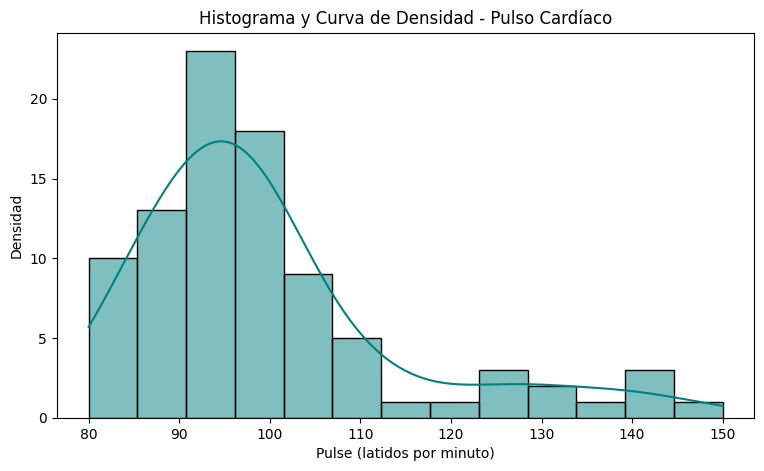

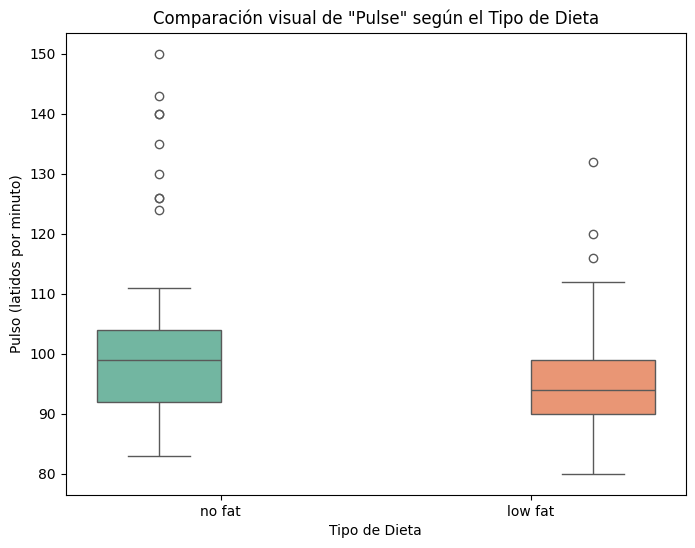

In [27]:
#Histograma de pulse
plt.figure(figsize=(9, 5))
sns.histplot(df['pulse'], kde=True, color="teal", edgecolor="black")
plt.title('Histograma y Curva de Densidad - Pulso Cardíaco')
plt.xlabel('Pulse (latidos por minuto)')
plt.ylabel('Densidad')
plt.show()

#Boxplot de pulse por dieta
plt.figure(figsize=(8, 6))
sns.boxplot(x='diet',y='pulse',hue='diet',data=df,palette='Set2',legend=False)
plt.title('Comparación visual de "Pulse" según el Tipo de Dieta')
plt.xlabel('Tipo de Dieta')
plt.ylabel('Pulso (latidos por minuto)')
plt.show()

**Interpretación:**
- Histograma: observamos la distribución general de las frecuencia del pulso, esto evidencia los agrupamiento entre estados de reposo y la actividad física.
- Boxplot por dieta: las medianas y cajas de los grupos de dieta (low fat y non fat) muestran un alto grado de solapamiento, lo que sugiere a simple vista que el tipo de dieta por sí solo no altera radicalmente la distribución del pulson sin tomar en cuenta el tiempo o la intensidad de la actividad como tal.

## 2. Correlación y regresión lineal

### Correlación de Perason entre time y pulse

In [34]:
pearson_corr, p_valor = stats.pearsonr(df['time_num'], df['pulse'])

print(f"Coeficiente de Correlación de Pearson: {pearson_corr:.4f}")
print(f"Valor p: {p_valor:.6f}")

Coeficiente de Correlación de Pearson: 0.3104
Valor p: 0.002906


**Interpretación:**
- Existe una correlación positiva y estadísticamente significativa, ya que p<0.05 entre el tiempo de ejercicio y el pulso. Esto confirma que a mayor duración de la actividad física, el pulso cardíaco de los sujetos tiende a incrementar de forma lineal.

### Regresión lineal simple de pulse sobre time

                            OLS Regression Results                            
Dep. Variable:                  pulse   R-squared:                       0.105
Model:                            OLS   Adj. R-squared:                  0.085
Method:                 Least Squares   F-statistic:                     5.113
Date:                Tue, 17 Nov 2026   Prob (F-statistic):            0.00795
Time:                        11:11:51   Log-Likelihood:                -365.07
No. Observations:                  90   AIC:                             736.1
Df Residuals:                      87   BIC:                             743.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         93.1333      2.595     35.

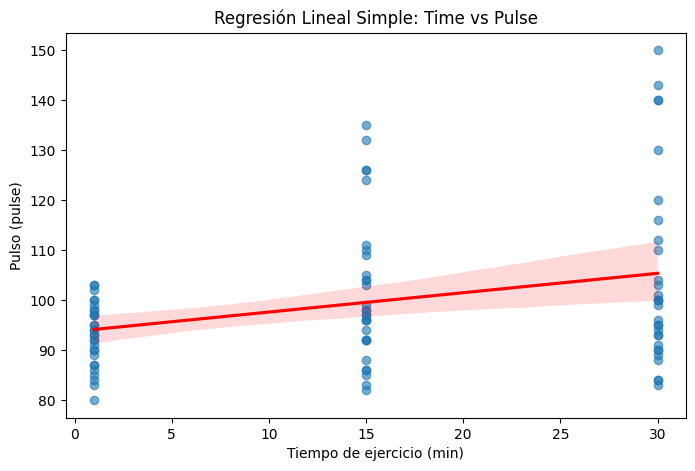

In [44]:
#Crear una copia del dataframe
df_clean = df.copy()

#Forzamos la conversión
x_vals = pd.to_numeric(df_clean['time'].astype(str).str.extract(r'(\d+)')[0], errors='coerce').to_numpy(dtype=float)
y_vals = pd.to_numeric(df_clean['pulse'], errors='coerce').to_numpy(dtype=float)
# Ajustar el modelo
modelo_simple = smf.ols('pulse ~ time', data=df_clean).fit()
print(modelo_simple.summary())

#Gráfico
plt.figure(figsize=(8, 5))
sns.regplot(x=x_vals, y=y_vals, scatter_kws={'alpha':0.6}, line_kws={'color': 'red'})
plt.title('Regresión Lineal Simple: Tiempo vs Pulso')
plt.xlabel('Tiempo de ejercicio (min)')
plt.ylabel('Pulso (pulse)')
plt.show()

**Interpretación:**
- El gráfico de dispersión y la recta de regresión muestran una relación directa y positiva entre el tiempo de ejercicio y el pulso cardíaco. A medida que incrementa la duración de la actividad física (pasando de 1 a 15 y 30 minutos), la línea de tendencia asciende progresivamente.

- Se observa claramente que las mediciones se concentran en tres momentos temporales específicos del experimento (1 min, 15 min y 30 min). En el minuto 30 la dispersión y los valores máximos de pulso son notablemente mayores debido al esfuerzo acumulado.

- La pendiente de la recta cuantifica el cambio promedio en las pulsaciones por cada minuto adicional de ejercicio. Asimismo, la banda de confianza sombreada en rojo y el coeficiente de determinación ($R^2$) resumen la capacidad explicativa del modelo lineal sobre la variabilidad global del pulso.


### Regresión lineal múltiple añadiendo id 

In [40]:
# Ajustar regresión lineal múltiple incluyendo id
modelo_multiple = smf.ols('pulse ~ time + id', data=df).fit()
print(modelo_multiple.summary())

print(f"\nComparación de R2 Ajustado:")
print(f"Modelo Simple: {modelo_simple.rsquared_adj:.4f}")
print(f"Modelo Múltiple (time + id): {modelo_multiple.rsquared_adj:.4f}")

                            OLS Regression Results                            
Dep. Variable:                  pulse   R-squared:                       0.566
Model:                            OLS   Adj. R-squared:                  0.551
Method:                 Least Squares   F-statistic:                     37.42
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.43e-15
Time:                        11:09:39   Log-Likelihood:                -332.49
No. Observations:                  90   AIC:                             673.0
Df Residuals:                      86   BIC:                             683.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         75.1667      2.614     28.

**Interpretación:**
- No tiene sentido incluir id, como variable cuantitativa continua es un error conceptual. El id es un código categórico de identificación de cada sujeto; tratarlo como número implica asumir que un individuo con ID 30 tiene como 30 veces más pulso, lo cual carece de sentido físico.  

## 3. Correlación y regresión logística

### Creación de la variable binaria de pulso_alto

In [47]:
#Definimos el umbral
mediana_pulse = df['pulse'].median()
df['pulso_alto'] = (df['pulse'] > mediana_pulse).astype(int)

print("Frecuencia de pulso_alto:")
print(df['pulso_alto'].value_counts())

Frecuencia de pulso_alto:
pulso_alto
0    46
1    44
Name: count, dtype: int64


### Regresión logística simple con time

In [50]:
#Ajustar regresión logística simple
log_simple = smf.logit('pulso_alto ~ time', data=df).fit()
print(log_simple.summary())

#Calculo de Odds
odds = np.exp(log_simple.params)
print("\nODDS RATIOS (Modelo simple)")
print(odds)

Optimization terminated successfully.
         Current function value: 0.677438
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:             pulso_alto   No. Observations:                   90
Model:                          Logit   Df Residuals:                       87
Method:                           MLE   Df Model:                            2
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.02232
Time:                        11:15:34   Log-Likelihood:                -60.969
converged:                       True   LL-Null:                       -62.361
Covariance Type:            nonrobust   LLR p-value:                    0.2487
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.5465      0.379     -1.443      0.149      -1.289       0.196
time[T.15 min]   

**Interpretación:** 
- El Odds Ratio que se asocia al tiempo, indica cómo cambian los odds (la relación entre que el evento ocurra o no) de registrar un pulso superior a la mediana ppor cada minuto adicional de ejercicio. 
- Un valor superior a 1 confirma que a mayor tiempo de actividad, la probabilidad de superar la mediana del pulso aumenta drásticamente. 


### Regresión logística múltiple

In [53]:
#Codificar la variable diet (0 para low fat, 1 para no fat)
df['diet_num'] = df['diet'].map({'low fat': 0, 'no fat': 1})

#Ajustar regresión logística múltiple
log_multiple = smf.logit('pulso_alto ~ time + diet_num', data=df).fit()
print(log_multiple.summary())

#Calcular Odds para el modelo múltiple
odds_m = np.exp(log_multiple.params)
print("\nODDS (Modelo Múltiple)")
print(odds_m)

Optimization terminated successfully.
         Current function value: 0.651703
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:             pulso_alto   No. Observations:                   90
Model:                          Logit   Df Residuals:                       86
Method:                           MLE   Df Model:                            3
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.05946
Time:                        11:19:50   Log-Likelihood:                -58.653
converged:                       True   LL-Null:                       -62.361
Covariance Type:            nonrobust   LLR p-value:                   0.05977
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.1083      0.433     -0.250      0.803      -0.958       0.741
time[T.15 min]   

**Interpretación:**
- La regresión logística múltiple permite evaluar el efecto simultáneo del tiempo de ejercicio y el tipo de dieta sobre la probabilidad de tener un pulso alto. Si el intervalo de Odds de la dita incluye el 1, se concluye que el tipo de diesta no impacta estadísticamente sobre la probabilidad de tener un pulso alto una vez controlado el tiempo de ejercicio.

- Los Odds Ratios de 2.36 (para 15 minutos) y 2.05 (para 30 minutos) indican que, en comparación con el tiempo base, realizar ejercicio durante 15 o 30 minutos incrementa de manera sustancial las probabilidades (odds) de registrar un pulso superior a la mediana, manteniendo constante el tipo de dieta.

- El coeficiente asociado a la dieta muestra un Odds de 0.39. No obstante, para una interpretación rigurosa, se debe evaluar su intervalo de confianza: si el intervalo incluye el valor 1, se concluye que el tipo de dieta no ejerce un impacto estadísticamente significativo sobre la probabilidad de tener un pulso alto una vez que se controla el efecto de la duración del ejercicio.

## 4. Interpretación final y limitaciones

El análisis demuestra una relación directa, positiva y significativa entre la duración del ejercicio y la frecuencia cardíaca (pulso). Los sujetos que se sometieron a mayor tiempo de actividad física presentaron de forma continua pulsaciones más elevadas y mayor probabilidad de clasificar en el grupo de pulso alto. Además, al controlar el tiempo de ejercicio en los modelos con múltiples variables, se observa que la variación del pulso responde fundamentalmente al esfuerzo físico y no a la dieta.  

En cuanto a las limitaciones del DataSet, en primer lugar, el conjunto de datos evalúa los mismos sujetos (id) en múltiples momentos temporales, lo que genera dependencia interna entre las observaciones que la regresión estándar no contempla. Por último, el número total de observaciones (90 registros) es limitado, lo que restringe el poder estadístico para modelar la interacción compleja sin realizar un sobreajuste. 